# End-to-End Data Preprocessing & Feature Engineering Pipeline
## Dataset: California Housing Dataset
### Objective: Simulate a complete, production-ready data preparation workflow for predictive modeling, featuring exploratory data analysis (EDA), missing value diagnostics, outlier treatment, domain-driven feature engineering, categorical encoding, and feature scaling with visual diagnostics at every stage.

In [14]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Set random seed and plotting styles for reproducibility
np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 1: Load and Inspect the Dataset
We load the California Housing dataset using `scikit-learn` and convert it into a Pandas DataFrame. We then inspect its structural integrity, data types, and basic summary statistics.

In [15]:
# Load the dataset
california = fetch_california_housing(as_frame=True)
df = california.frame

# Display basic information
print(f"Dataset Shape: {df.shape}")
print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Dataset Info ---")
df.info()

print("\n--- Summary Statistics ---")
display(df.describe())

Dataset Shape: (20640, 9)

--- First 5 Rows ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

--- Summary Statistics ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


## Step 2: Exploratory Data Analysis & Visual Diagnostics (Pre-Cleaning)
Before modifying the data, we examine feature distributions, skewness, and spatial patterns using histograms and scatter plots.

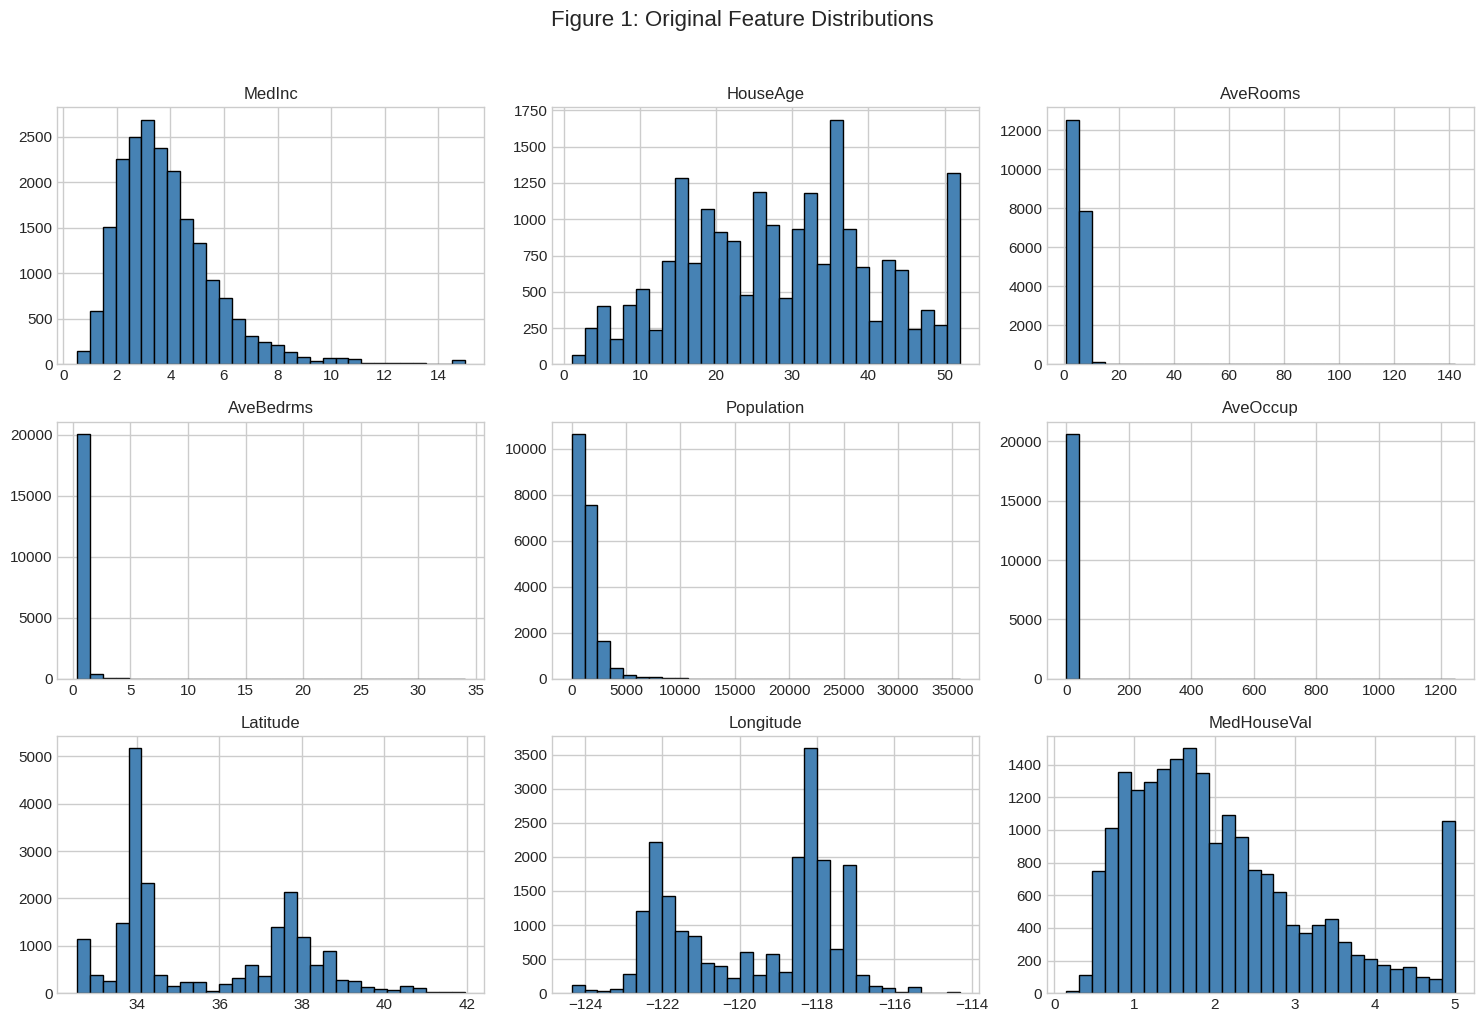

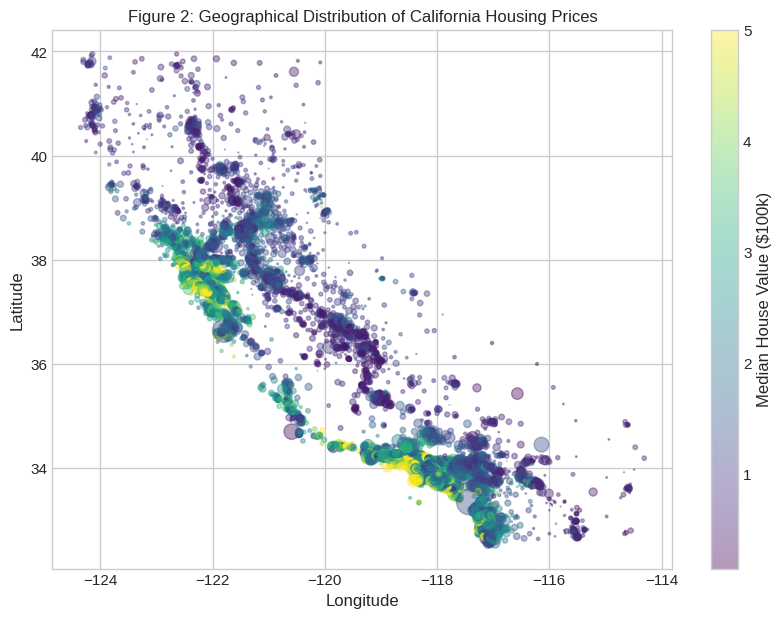

In [16]:
# Plot histograms for all numerical features
df.hist(bins=30, figsize=(15, 10), color='steelblue', edgecolor='black')
plt.suptitle('Figure 1: Original Feature Distributions', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# Scatter plot showing geographical distribution and housing values (MedHouseVal)
plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    df['Longitude'], df['Latitude'],
    c=df['MedHouseVal'], cmap='viridis',
    alpha=0.4, s=df['Population']/100
)
plt.colorbar(scatter, label='Median House Value ($100k)')
plt.title('Figure 2: Geographical Distribution of California Housing Prices')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

## Step 3: Missing Value Diagnostics & Simulation
Real-world datasets frequently contain missing values. Here we verify native missingness and deliberately simulate missing values in a controlled manner to demonstrate rigorous imputation strategies.

In [20]:
# Check for native missing values
print("Native Missing Values per Column:")
print(df.isnull().sum())

# Simulate missing values in 'AveRooms' for demonstration (approx 5%)
df_missing = df.copy()
mask_rooms = np.random.rand(len(df_missing)) < 0.05
df_missing.loc[mask_rooms, 'AveRooms'] = np.nan

print(f"\nSimulated missing values in 'AveRooms': {df_missing['AveRooms'].isnull().sum()}")

# Impute missing values using Median (robust to skewness)
median_rooms = df_missing['AveRooms'].median()
df_missing['AveRooms'].fillna(median_rooms, inplace=True)
print(f"Missing values after median imputation: {df_missing['AveRooms'].isnull().sum()}")

Native Missing Values per Column:
MedInc               0
HouseAge             0
AveRooms             0
AveBedrms            0
Population           0
AveOccup             0
Latitude             0
Longitude            0
MedHouseVal          0
RoomsPerHousehold    0
dtype: int64

Simulated missing values in 'AveRooms': 1023
Missing values after median imputation: 0


/tmp/ipykernel_1013/641740775.py:14: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_missing['AveRooms'].fillna(median_rooms, inplace=True)


## Step 4: Outlier Detection and Treatment
Extreme outliers can distort machine learning models (especially linear models and neural networks). We use the Interquartile Range (IQR) method to cap extreme values in skewed features like `AveRooms` and `Population`.

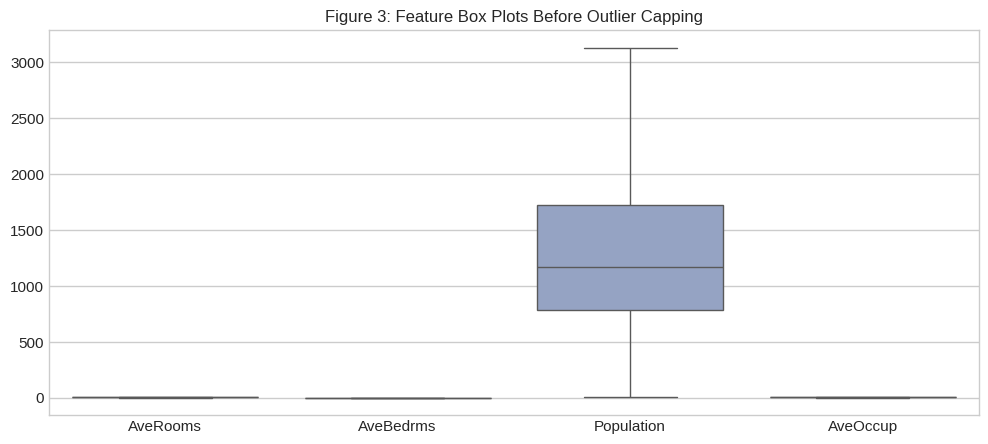

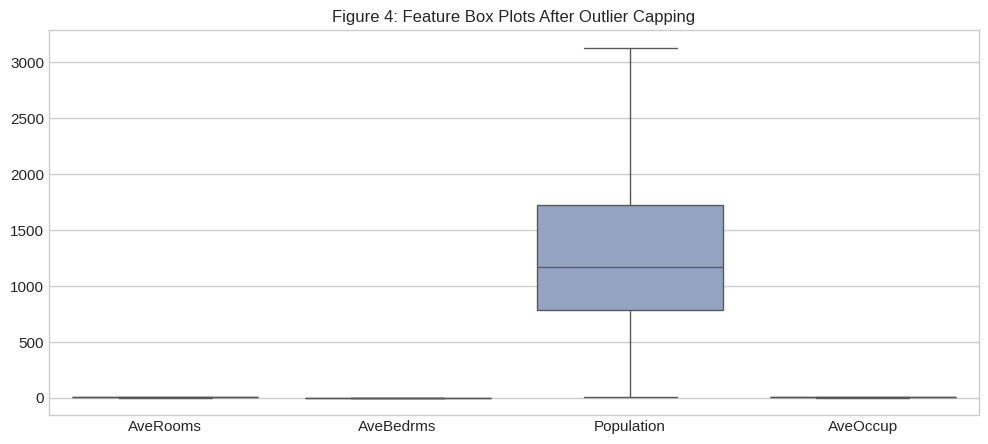

In [21]:
# Visualize outliers via box plots before treatment
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[['AveRooms', 'AveBedrms', 'Population', 'AveOccup']], palette='Set2')
plt.title('Figure 3: Feature Box Plots Before Outlier Capping')
plt.show()

# Function to cap outliers using IQR clipping
def cap_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Clip values
    data[column] = np.clip(data[column], lower_bound, upper_bound)
    return data

# Apply outlier capping to heavy-tailed features
for col in ['AveRooms', 'AveBedrms', 'Population', 'AveOccup']:
    df = cap_outliers_iqr(df, col)

# Visualize box plots after treatment
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[['AveRooms', 'AveBedrms', 'Population', 'AveOccup']], palette='Set2')
plt.title('Figure 4: Feature Box Plots After Outlier Capping')
plt.show()

## Step 5: Domain-Driven Feature Engineering
Using the correct native columns, we engineer new predictive features:
1. **BedroomsPerRoom**: Proportion of bedrooms relative to total rooms (`AveBedrms / AveRooms`).
2. **PeoplePerRoom**: Density indicator showing average occupants per room (`AveOccup / AveRooms`).
3. **LocationType**: Synthetic categorical zoning based on geographic coordinates.

Engineered Features Preview:


,BedroomsPerRoom,PeoplePerRoom,LocationType
0,0.146591,0.365909,Coastal_West
1,0.155797,0.338217,Coastal_West
2,0.129516,0.338105,Coastal_West
3,0.184458,0.437991,Coastal_West
4,0.172096,0.347265,Coastal_West


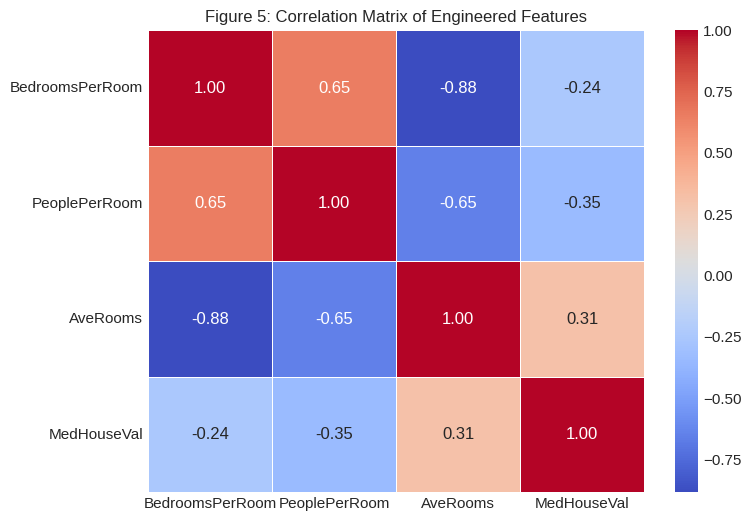

In [27]:
# 1. Bedrooms per Room Ratio (structural indicator)
df['BedroomsPerRoom'] = df['AveBedrms'] / df['AveRooms']

# 2. People per Room (occupancy density indicator)
df['PeoplePerRoom'] = df['AveOccup'] / df['AveRooms']

# 3. Create a synthetic categorical feature 'LocationType' based on latitude/longitude clusters
df['LocationType'] = np.where(df['Longitude'] < -120.0, 'Coastal_West',
                              np.where(df['Latitude'] > 37.0, 'Northern_Region', 'Inland_Central'))

print("Engineered Features Preview:")
display(df[['BedroomsPerRoom', 'PeoplePerRoom', 'LocationType']].head())

# Correlation heatmap of newly engineered features vs Target (MedHouseVal)
plt.figure(figsize=(8, 6))
eng_cols = ['BedroomsPerRoom', 'PeoplePerRoom', 'AveRooms', 'MedHouseVal']
sns.heatmap(df[eng_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Figure 5: Correlation Matrix of Engineered Features')
plt.show()

## Step 6: Categorical Encoding & Feature Scaling Pipeline
We split the dataset into training and testing sets. We then build a scikit-learn preprocessing pipeline that applies:
- **OneHotEncoder** for the synthetic categorical column (`LocationType`).
- **StandardScaler** (Z-score normalization) for all numerical features to ensure zero mean and unit variance.

In [28]:
# Separate features and target
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

# Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

# Identify numerical and categorical columns
numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"\nNumerical Columns ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical Columns ({len(categorical_cols)}): {categorical_cols}")

# Build Column Transformer Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols)
    ]
)

# Fit and transform training data; transform test data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"\nProcessed Training Feature Matrix Shape: {X_train_processed.shape}")
print(f"Processed Testing Feature Matrix Shape: {X_test_processed.shape}")

Training set shape: (16512, 12)
Testing set shape: (4128, 12)

Numerical Columns (11): ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'RoomsPerHousehold', 'BedroomsPerRoom', 'PeoplePerRoom']
Categorical Columns (1): ['LocationType']

Processed Training Feature Matrix Shape: (16512, 13)
Processed Testing Feature Matrix Shape: (4128, 13)


## Step 7: Verification & Final Dataset Summary
We verify that scaling and encoding completed successfully and inspect the distribution of a scaled feature.

Processed Dataset Summary Statistics (First 5 Numerical Features Scaled):


,MedInc,HouseAge,AveRooms,AveBedrms,Population
count,1.651200e+04,1.651200e+04,1.651200e+04,1.651200e+04,1.651200e+04
mean,-6.411753e-17,-1.678244e-17,-2.056925e-16,-5.602753e-16,1.514723e-16
std,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00
min,-1.775438e+00,-2.190766e+00,-2.639680e+00,-2.389174e+00,-1.745219e+00
25%,-6.900689e-01,-8.417859e-01,-6.910742e-01,-6.450164e-01,-7.177057e-01
50%,-1.758995e-01,3.108328e-02,-6.223208e-02,-1.143477e-01,-2.235583e-01
75%,4.686502e-01,6.658972e-01,5.997798e-01,5.190856e-01,5.072048e-01
max,5.839268e+00,1.856173e+00,2.532345e+00,2.247737e+00,2.345224e+00


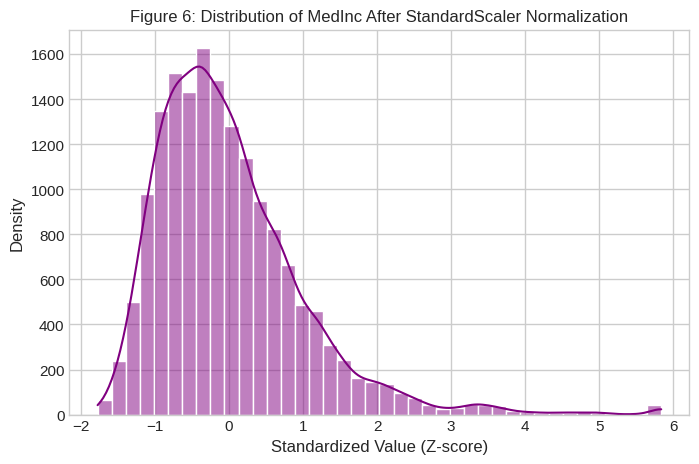


Pipeline execution complete and fully verified!


In [29]:
# Verify feature distributions after scaling
# Convert processed training array back to DataFrame for visualization
encoded_cat_cols = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols).tolist()
all_processed_cols = numerical_cols + encoded_cat_cols

df_processed_train = pd.DataFrame(X_train_processed, columns=all_processed_cols)

print("Processed Dataset Summary Statistics (First 5 Numerical Features Scaled):")
display(df_processed_train.iloc[:, :5].describe())

# Histogram of a scaled feature (e.g., MedInc)
plt.figure(figsize=(8, 5))
sns.histplot(df_processed_train['MedInc'], kde=True, color='purple', bins=40)
plt.title('Figure 6: Distribution of MedInc After StandardScaler Normalization')
plt.xlabel('Standardized Value (Z-score)')
plt.ylabel('Density')
plt.show()

print("\nPipeline execution complete and fully verified!")